# Exercício

1. Gere uma amostra de tamanho $M$ de uma exponencial através do método de inversão visto em sala. Compare com uma exponencial gerada pelo numpy via histogramas. Comparem também com a densidade real da exponencial $f(x) = \lambda e^{-\lambda x}$ (isto é, seu histograma normalizado tem que ficar igual essa curva).

2. Agora considere $T_n = X_n / n$ onde $X_n$ é uma Geométrica com parâmetro $\lambda/n$. Mostre que quando $n$ é grande, isso se aproxima de uma exponencial.

3. Considere agora $X_1, X_2, \ldots$ variáveis aleatórias i.i.d. com distribuição Exponencial de parâmetro $\lambda$. Vá somando essas variáveis até que a soma ultrapasse $1$ e conte quantas delas foram somadas antes de ultrapassar $1$. Repita esse procedimento $M$ vezes e mostre empiricamente que essa quantidade segue aproximadamente uma Poisson de parâmetro $\lambda$. Compare o histograma obtido com uma Poisson gerada pelo numpy e com a função de probabilidade real da Poisson.

Aplicar a inversa para F(x) = 2x, para x e [0,1]

Aplicamos a integral de 0 até t, na Fx = t^2 , agora precisamos encontrar a inversa desse numero. u = t^2 -> u^1/2 = t . Fx^-1(u) = u^1/2

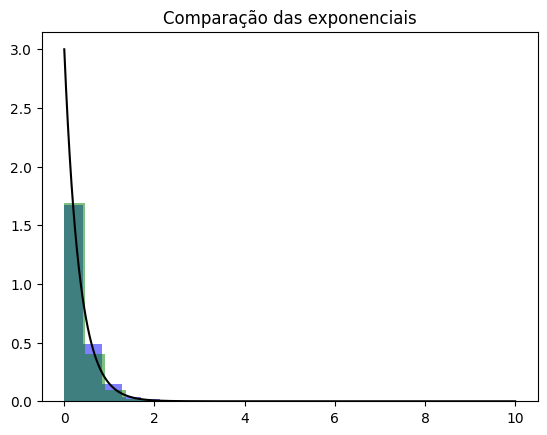

In [26]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

M = 1000
amostra_exp = []
for i in range(M):
  lamb = 3
  u = np.random.uniform()
  exp = -np.log(u)/lamb
  amostra_exp.append(exp)

#Como eu ploto a densidade?

x = np.linspace(0, 10, 1000)
y = lamb * np.exp(-lamb*x)
plt.plot(x,y, color='black')
expo = np.random.exponential(1/lamb, size=M)
plt.hist(expo, alpha=.5, bins=5, color='blue', density=True)
plt.hist(amostra_exp, alpha=.5, bins=5, color='green', density=True)
plt.title('Comparação das exponenciais')
plt.show()

2. Agora considere $T_n = X_n / n$ onde $X_n$ é uma Geométrica com parâmetro $\lambda/n$. Mostre que quando $n$ é grande, isso se aproxima de uma exponencial.

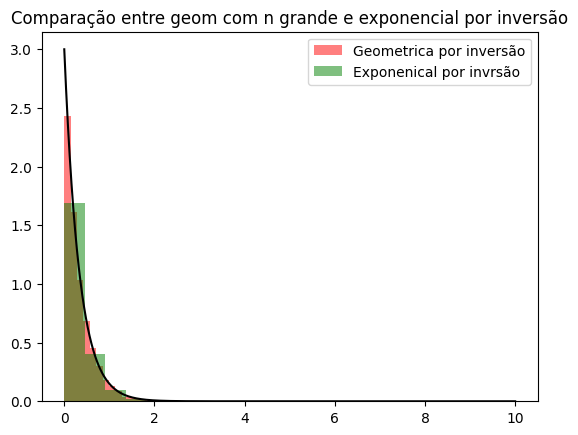

In [35]:
amostra_geo = []
lamb = 3
n = 10000
p = lamb/n
for i in range(M):
  u = np.random.uniform()
  Xn = np.ceil(np.log(u)/np.log(1-p))
  Tn = Xn/n
  amostra_geo.append(Tn)
x = np.linspace(0, 10, 1000)
y = lamb * np.exp(-lamb*x)
plt.plot(x,y, color='black')
plt.hist(amostra_geo, bins = 20, alpha=.5, color = 'red', density=True, label = 'Geometrica por inversão')
plt.hist(amostra_exp, alpha=.5, bins=5, color='green', density=True, label= 'Exponenical por invrsão')
plt.legend()
plt.title('Comparação entre geom com n grande e exponencial por inversão')
plt.show()

3. Considere agora $X_1, X_2, \ldots$ variáveis aleatórias i.i.d. com distribuição Exponencial de parâmetro $\lambda$. Vá somando essas variáveis até que a soma ultrapasse $1$ e conte quantas delas foram somadas antes de ultrapassar $1$. Repita esse procedimento $M$ vezes e mostre empiricamente que essa quantidade segue aproximadamente uma Poisson de parâmetro $\lambda$. Compare o histograma obtido com uma Poisson gerada pelo numpy e com a função de probabilidade real da Poisson.

(array([0.16441667, 0.18108333, 0.18883333, 0.14266667, 0.08275   ,
        0.06341667, 0.00675   , 0.0025    , 0.0005    , 0.00041667]),
 array([ 0. ,  1.2,  2.4,  3.6,  4.8,  6. ,  7.2,  8.4,  9.6, 10.8, 12. ]),
 <BarContainer object of 10 artists>)

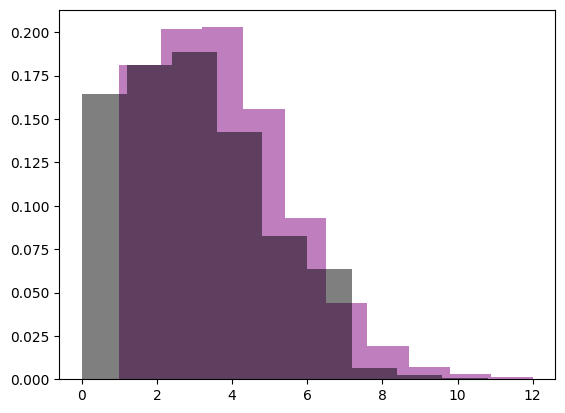

In [50]:
amostra_poi = []
lamb = 3
soma = 0
for i in range(M):
  soma = 0
  cont = 0
  while soma < 1:
    u = np.random.uniform()
    expo = -np.log(u)/lamb
    soma += expo
    cont += 1
  amostra_poi.append(cont)
plt.hist(amostra_poi, alpha=.5, color = 'purple', label='Poisson Inversão', density =True)
plt.hist(np.random.poisson(lamb, size=M), alpha=.5, label = 'Poisson numpy', density=True, color='black')